<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet4%20PBL/Praktikum%201%20(JS4)%20PBL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 1: Persiapan Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Membaca dataset cafes.csv dan reviews.csv
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')

# Agregasi data review per kafe
review_agg = df_reviews.groupby('cafe_id').agg({'rating': ['mean', 'count'], 'likes': 'sum'})
review_agg.columns = ['avg_review_rating', 'total_reviews_scraped', 'total_likes']
review_agg = review_agg.reset_index()

# Menggabungkan dataframe cafes dengan agregasi review
df = pd.merge(df_cafes, review_agg, on='cafe_id', how='left').fillna(0)

# Menampilkan 5 data teratas hasil penggabungan
df.head()

,cafe_id,name,address,latitude,longitude,rating,review_count,categories,phone,website,scraped_at,source_query,avg_review_rating,total_reviews_scraped,total_likes
0,ba4b512c-fa2d-4959-8384-8570c81121ec,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang,4.400000,30.0,0.0
1,528dfd21-83c6-4946-ab05-391e238caa4a,Nayanika Coffee & Eatery - Malang,"Jl. Brigjend Slamet Riadi No.173, Oro-oro Dowo...",-7.963825,112.627146,4.7,141,['Kafe'],0851-4820-4378,linktr.ee,2026-10-11T13:54:56.561971,cafe Kota Malang,4.866667,30.0,0.0
2,cb007499-1d5e-4613-8bbc-c0d30e17b2d2,The Grove Cafe Malang,"Jl. Wilis No.23, Gading Kasri, Kec. Klojen, Ko...",-7.972555,112.618455,4.6,1772,['Kafe'],0888-8299-000,0,2026-10-11T13:55:10.909678,cafe Kota Malang,4.217391,23.0,0.0
3,f4cd572c-a98d-4309-aa81-6018d889c9d6,Zocco Heritage,"Jl. Raya Lawang - Malang No.34, Klojen, Purwan...",-7.967561,112.633346,4.3,701,['Kedai Kopi'],0,instagram.com,2026-10-11T13:55:27.732707,cafe Kota Malang,4.133333,30.0,0.0
4,fdd5baff-4477-4188-abf8-4f2a00cf10ee,RASWARA COFFEE AND EATERY,"Jl. Suropati No.1, Klojen, Kec. Klojen, Kota M...",-7.976481,112.634028,4.3,686,['Kafe'],0822-3131-2363,instagram.com,2026-10-11T13:55:43.558923,cafe Kota Malang,3.666667,30.0,0.0


#Langkah 2: Seleksi Fitur

In [2]:
# Seleksi Fitur (Menggunakan kolom rating dan review_count)
X = df[['rating', 'review_count']]

# Menampilkan 5 baris pertama dari fitur yang dipilih
X.head()

,rating,review_count
0,4.7,528
1,4.7,141
2,4.6,1772
3,4.3,701
4,4.3,686


#Langkah 3: Plot Data Awal

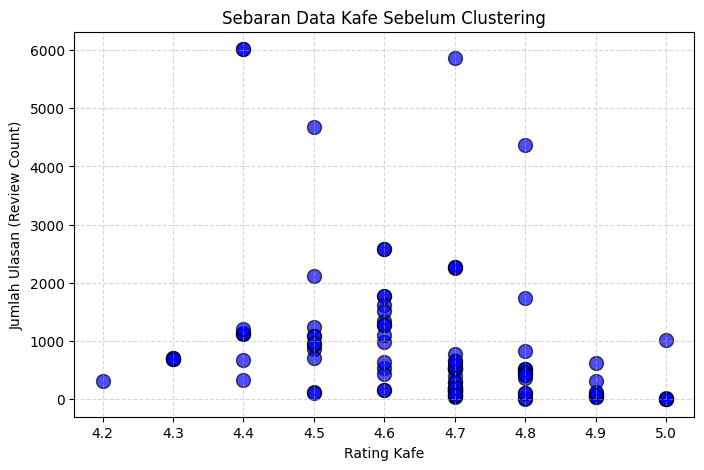

In [3]:
# Plot Data Berdasarkan Rating dan Review Count
plt.figure(figsize=(8, 5))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100, color='blue', edgecolor='k', alpha=0.7)
plt.xlabel("Rating Kafe")
plt.ylabel("Jumlah Ulasan (Review Count)")
plt.title("Sebaran Data Kafe Sebelum Clustering")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

#Langkah 4: Membuat Model KMeans (K = 2)

In [5]:
# Inisiasi obyek KMeans dengan k=2
cl_kmeans = KMeans(n_clusters=2, random_state=42)

# Fit dan predict model ke data X
y_kmeans = cl_kmeans.fit_predict(X)


#Langkah 5: Plot Hasil Cluster dan Centroid

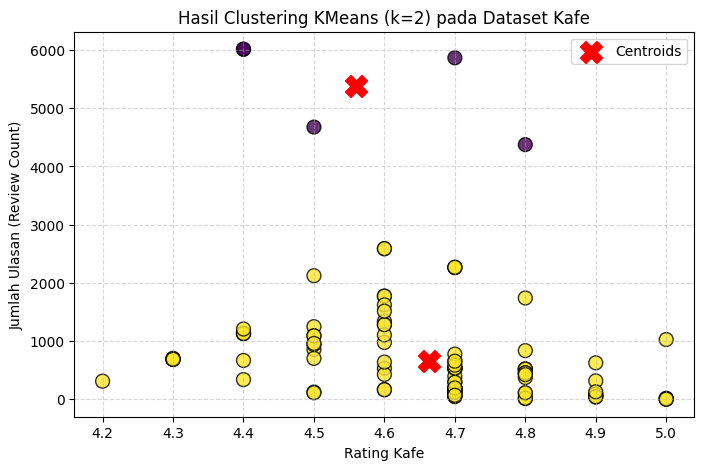

In [6]:
# Plot hasil cluster berdasarkan Rating dan Review Count
plt.figure(figsize=(8, 5))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100, c=y_kmeans, cmap='viridis', edgecolor='k', alpha=0.8)

# Plot centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=250, marker='X', label='Centroids')

plt.xlabel("Rating Kafe")
plt.ylabel("Jumlah Ulasan (Review Count)")
plt.title("Hasil Clustering KMeans (k=2) pada Dataset Kafe")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

#Langkah 6: Cek Nilai SSE (Inertia)

In [7]:
# Cek Nilai SSE
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 40400521.870829776


#Langkah 7: Implementasi Metode Elbow

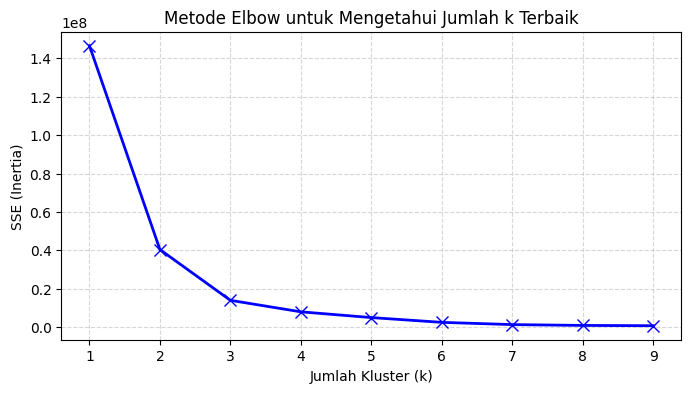

In [9]:
# List nilai SSE
sse = []
# Cari k terbaik dari 1-9
K = range(1, 10)

# Cek nilai SSE setiap k
for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42)
    kmeanModel.fit(X)
    sse.append(kmeanModel.inertia_)

# Plotting the Elbow graph
plt.figure(figsize=(8, 4))
plt.plot(K, sse, "bx-", linewidth=2, markersize=8)
plt.xlabel("Jumlah Kluster (k)")
plt.ylabel("SSE (Inertia)")
plt.title("Metode Elbow untuk Mengetahui Jumlah k Terbaik")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

#8: Cek Nilai SSE Setiap $k$

In [10]:
# Cek Nilai SSE setiap k
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')


k=1; SSE=146589023.54626256
k=2; SSE=40400521.870829776
k=3; SSE=13949541.903923078
k=4; SSE=7954474.761295548
k=5; SSE=4960970.292665534
k=6; SSE=2475529.4323322023
k=7; SSE=1299162.9649356478
k=8; SSE=875744.6382575757
k=9; SSE=717883.2970244755
